# Biểu diễn văn bản

## Mục tiêu

So sánh sáu cách biểu diễn mô tả sản phẩm: Bag of Words (BoW), TF-IDF unigram, TF-IDF unigram đến bigram, TF-IDF unigram đến trigram, trung bình vector Word2Vec và embedding từ mô hình đóng băng `sentence-transformers/all-MiniLM-L6-v2`. Đo dung lượng, độ tương đồng, mức tách theo danh mục, cấu trúc cụm và hiệu năng phân loại.

Đề yêu cầu đo số chiều, độ thưa, cosine, t-SNE và silhouette. Sentence Transformer nằm trong mục nâng cao và được nêu trong bảng điểm, nên chương thực hiện cả so sánh K-Means và Linear SVM. Word2Vec dùng Gensim với phiên bản nguồn cố định có bản sửa lỗi số học. Đề yêu cầu Word2Vec nhưng chưa ghi Gensim trong danh sách thư viện chung. [Đề đồ án](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/) · [EDA](01_eda.ipynb) · [Chuẩn hóa](02_normalization_tokenization.ipynb) · [Các phép so sánh từ dừng và hình thái](03_stopwords_morphology.ipynb)


## Phương pháp

Tái dựng `make_text_protocol(raw, test_size=.2, seed=42)`. Giữ nhãn, chuỗi gốc và vị trí bản ghi `row_id`. Dùng phép chuẩn hóa giữ số của chương 02 và regex chương 03. Giữ từ dừng và hình thái gốc. Cả sáu phương án nhận cùng nội dung gồm các token nối bằng dấu cách. Word2Vec dùng trực tiếp danh sách tương ứng. Mã có dấu phân cách có thể bị chia nhỏ và đầu vào MiniLM ít dấu câu hơn dữ liệu câu tự nhiên dùng để huấn luyện trước.

| Phân tích | Phạm vi khớp | Phạm vi chấm |
|---|---|---|
| Số chiều, cosine và cấu trúc | Tập huấn luyện | Cặp hoặc tập con cố định của tập huấn luyện |
| CV Linear SVM với ma trận thưa | Từ vựng, IDF và SVM mới trong từng phần huấn luyện | Phần xác thực tương ứng |
| CV Linear SVM với MiniLM | Bộ mã hóa công khai đóng băng, SVM khớp riêng từng phần huấn luyện | Phần xác thực tương ứng |

Tái tạo đúng năm fold theo nhóm chuỗi cơ sở ở chương 03, với seed 42 và dấu vân tay thành viên để đối chiếu. Word2Vec khớp toàn bộ tập huấn luyện chỉ dùng mô tả không gian. MiniLM có thể mã hóa trước vì trọng số đóng băng và không học từ tập dự án. Chuẩn L2 theo từng dòng không cần thống kê chung.

Với BoW và TF-IDF, dùng `min_df=2`, `max_features=30000`, bộ phân tích từ của thư viện, tách bằng `str.split`, không lặp bước chữ thường, với dải n-gram `(1,1)`, `(1,2)` và `(1,3)`. Bộ phân tích dạng hàm sẽ bỏ qua việc sinh n-gram nên cần giữ bộ phân tích từ. Năm cấu hình SVM dùng C = 1, squared hinge, LinearSVC dạng primal, seed 42, max_iter = 10000 và tol = 1e−4. Tập đánh giá 20% không dùng để chọn cấu hình.

Với cosine, chọn 600 cặp duy nhất cho mỗi lớp và 400 cặp cho mỗi cặp lớp, không ghép một mẫu với chính nó. Tổng cộng có 2.400 cặp cùng lớp và 2.400 cặp khác lớp, giữ nguyên mã ở mọi phương án. Chọn 300 dòng mỗi lớp bằng seed 42 cho hình học, cộng 1.200 dòng. Dùng giao các dòng có vector khác 0 để so sánh hình học. Trong thống kê cosine theo cặp, quy ước cosine bằng 0 nếu gặp vector 0 và ghi số cặp thuộc trường hợp này.

Chuẩn L2 từng vector. Silhouette chính dùng khoảng cách cosine trong không gian gốc, tính riêng theo nhãn thật và theo nhãn cụm. Dùng Euclid để kiểm tra độ nhạy. K-Means tối ưu khoảng cách Euclid với K = 4, k-means++, 10 lần khởi tạo, seed 42 và max_iter = 300. Tâm cụm không bị ràng buộc chuẩn 1. ARI đo mức trùng giữa phân cụm và nhãn thật. Riêng t-SNE dùng TruncatedSVD(50, n_iter=7, seed=42) trên tập con chung, chuẩn L2 lại rồi chiếu Euclid với perplexity 30, init=PCA, learning_rate=auto, max_iter=1000 và seed 42.


## Triển khai

Dùng kernel `hcmus-wids` mới từ thư mục repo hoặc `book/text/`. Các hàm đo và dựng mô hình trong `src/text_representations.py` hỗ trợ kiểm thử với đầu vào có đáp án biết trước. Dùng tệp `data/raw/ecommerce/ecommerceDataset.csv` gốc. Khi thiếu đúng phiên bản mô hình, tải tệp công khai vào `.cache/huggingface/`. Các kết quả lưu sẵn phục vụ đọc sách tĩnh. [Cài đặt và tái lập](../../README.md)


In [1]:
from pathlib import Path
from collections import Counter
from importlib.metadata import version, distribution
from time import perf_counter
import hashlib
import json
import platform
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, accuracy_score, adjusted_rand_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from gensim.models import Word2Vec
import torch
from sentence_transformers import SentenceTransformer
from huggingface_hub import snapshot_download
from huggingface_hub.utils import disable_progress_bars
from transformers.utils import logging as transformers_logging

ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents)
           if (p/"myst.yml").is_file() and (p/"src/text_representations.py").is_file()),None)
if ROOT is None: raise RuntimeError("Start inside this repository.")
if Path(sys.prefix).resolve()!=(ROOT/".venv").resolve():
    raise RuntimeError("Select the project's existing .venv kernel (hcmus-wids), restart and Run All.")
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.reporting import display_report, prose, show_figure, show_table
from src.text_data import LABELS, read_ecommerce, make_text_protocol
from src.text_preprocessing import normalize_default, lexical_tokens
from src.text_representations import (fixed_text_folds, word_vectorizer, sparse_svm_pipeline,
    linear_svm, matrix_profile, row_norms, paired_cosines, sample_document_pairs, balanced_subset,
    stable_word_hash, mean_word_vectors, frozen_sentence_vectors, safe_silhouette, word2vec_numeric_guard)
SEED=42
DATA_PATH=ROOT/"data/raw/ecommerce/ecommerceDataset.csv"
MODEL_NAME="sentence-transformers/all-MiniLM-L6-v2"
MODEL_REVISION="1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
MODEL_CACHE=ROOT/".cache/huggingface"
MODEL_FILES=["config.json","modules.json","config_sentence_transformers.json","sentence_bert_config.json",
             "tokenizer.json","tokenizer_config.json","special_tokens_map.json","vocab.txt",
             "model.safetensors","1_Pooling/config.json"]
SPARSE_CONFIGS={"BoW":(False,1),"TF-IDF 1":(True,1),"TF-IDF 1-2":(True,2),"TF-IDF 1-3":(True,3)}
MAX_FEATURES=30000
MIN_DF=2
PAIR_SEED=SUBSET_SEED=42
PER_CLASS=300
W2V_PARAMETERS=dict(vector_size=100,window=5,min_count=2,sg=0,cbow_mean=1,negative=5,hs=0,
                    sample=1e-3,epochs=10,workers=1,seed=42,sorted_vocab=1,hashfxn=stable_word_hash)
torch.set_num_threads(4);torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
disable_progress_bars();transformers_logging.disable_progress_bar()
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":140})

print("Python",platform.python_version(),"|",platform.system(),platform.machine(),"| CPU only; torch threads=4, BLAS=2")
packages=["numpy","scipy","scikit-learn","gensim","sentence-transformers","torch","transformers","tokenizers"]
show_table(pd.DataFrame({"package":packages,"version":[version(p) for p in packages]}),index=False)

Matplotlib is building the font cache; this may take a moment.


/Users/nguyenduchung/data-mining-preprocessing/data-mining-preprocessing/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1127 22:43:55.909000 38595 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Python 3.13.3 | Darwin arm64 | CPU only; torch threads=4, BLAS=2


Thư viện,Phiên bản
numpy,2.5.4
scipy,1.18.1
scikit-learn,1.9.1
gensim,4.4.0
sentence-transformers,6.3.0
torch,2.15.0
transformers,5.23.0
tokenizers,0.23.3


In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place the original Kaggle ecommerceDataset.csv in data/raw/ecommerce/; see README.")
raw_sha256_before=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw=read_ecommerce(DATA_PATH);raw_snapshot=raw.copy(deep=True)
protocol=make_text_protocol(raw,test_size=.2,seed=42)
train=protocol["train"].copy();assessment_ids=protocol["test"].row_id.copy()
observed_fingerprints={"source":raw_sha256_before,
    "train":hashlib.sha256(train.row_id.to_numpy(dtype="<i8").tobytes()).hexdigest(),
    "assessment":hashlib.sha256(assessment_ids.to_numpy(dtype="<i8").tobytes()).hexdigest()}
REFERENCES={"source":"1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f",
    "train":"b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c",
    "assessment":"737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6"}
fingerprint_table=pd.DataFrame({"observed":observed_fingerprints,"Stage02_03_reference":REFERENCES})
fingerprint_table["matches"]=fingerprint_table.observed.eq(fingerprint_table.Stage02_03_reference)
assert fingerprint_table.matches.all(),"Source/protocol difference: investigate, never force reference counts."
assert set(train.row_id).isdisjoint(assessment_ids)
assert set(train.canonical_key).isdisjoint(protocol["test"].canonical_key)
base_text=train.text.map(normalize_default)
base_tokens=base_text.map(lexical_tokens)
input_text=base_tokens.map(" ".join)
y=train.label.to_numpy()
folds,group_ids=fixed_text_folds(y,base_text,seed=42)
# References are Stage 03's saved validation-row fingerprints, not scores or substituted counts.
STAGE03_FOLD_REFERENCES=['a0591b021b54dbb038950b5ee958c7a4471d42e158362b9311671606902d55a8', '29eddd5cb4f05d942fd02db71d26816bf9b737b07c6ea19ffce6028aee5833e8', '042b87ae65a87a38063834f441bad3ee6bf4905a6c793a083b16479954c1fcc4', 'e26601929e364bf80de2fec02d4f1904111b5c4d4cd040f8ae68c40bf6c344ed', '758b4dffa158c7c4276489eb83fb8c73de16a636a7820cd2002825b01249dc7f']
fold_records=[];fold_support=[];validation_coverage=np.zeros(len(train),dtype=int)
for number,(fitting,validation) in enumerate(folds,1):
    overlap=len(set(group_ids[fitting])&set(group_ids[validation]))
    digest=hashlib.sha256(np.sort(train.iloc[validation].row_id.to_numpy(dtype="<i8")).tobytes()).hexdigest()
    assert overlap==0 and set(fitting).isdisjoint(validation)
    assert digest==STAGE03_FOLD_REFERENCES[number-1]
    assert set(y[fitting])==set(LABELS) and set(y[validation])==set(LABELS)
    validation_coverage[validation]+=1
    fold_records.append({"fold":number,"fitting_N":len(fitting),"validation_N":len(validation),
                         "group_overlap":overlap,"validation_ID_SHA256":digest})
    for label in LABELS:
        fold_support.append({"fold":number,"label":label,"fit_N":int((y[fitting]==label).sum()),
                             "validation_N":int((y[validation]==label).sum())})
assert np.all(validation_coverage==1)
fold_table=pd.DataFrame(fold_records)
normalized_group_counts=base_text.value_counts()
protocol_measurements=pd.Series({"raw_N":len(raw),"canonical_eligible_N":len(protocol["corpus"]),
    "TRAIN_N":len(train),"assessment_N":len(assessment_ids),"normalized_duplicate_groups":int(normalized_group_counts.ge(2).sum()),
    "normalized_redundant_rows":int((normalized_group_counts-1).sum()),
    "empty_common_inputs":int(input_text.eq("").sum()),"lexical_types":len(set(t for tokens in base_tokens for t in tokens))},name="measured")

## Kết quả

### Nguồn, thành viên từng fold và phạm vi phân tích

Checksum dữ liệu, thành viên phép chia và dấu vân tay phần xác thực của năm fold khớp với chương 02–03. Chỉ dùng mã dòng và khóa của tập 20% để kiểm tra ranh giới. Token số và token một ký tự đủ điều kiện xuất hiện. Các ngưỡng tần suất thuộc từng biểu diễn.


In [3]:
show_table(protocol_measurements.to_frame())
show_table(fingerprint_table,"Checksum nguồn và dấu vân tay từng tập",collapse=True)
class_support=train.label.value_counts().reindex(LABELS).rename("TRAIN_N").to_frame()
class_support["TRAIN_pct"]=100*class_support.TRAIN_N/len(train)
show_table(class_support.round(3))
show_table(fold_table.drop(columns="validation_ID_SHA256"),"Các fold dùng chung với chương 03",index=False)
show_table(pd.DataFrame(fold_support),"Số mẫu mỗi lớp ở phần huấn luyện và xác thực từng fold",collapse=True,index=False)
show_table(fold_table[["fold","validation_ID_SHA256"]],"Đối chiếu thành viên fold với chương 03",collapse=True,index=False)
display_report(prose((
                 f"Từ {len(raw):,} dòng gốc còn {len(protocol['corpus']):,} mô tả đủ điều kiện. "
                 f"Tập huấn luyện có **{len(train):,}** dòng và tập đánh giá có **{len(assessment_ids):,}** dòng. "
                 f"Có {int(protocol_measurements.normalized_duplicate_groups)} nhóm trùng sau chuẩn hóa "
                 f"và {int(protocol_measurements.normalized_redundant_rows)} dòng dư trong tập huấn luyện. Các nhóm giống hệt nhau được giữ chung trong CV."
                 )))

,Giá trị đo
raw_N,50425
canonical_eligible_N,27752
TRAIN_N,22201
assessment_N,5551
normalized_duplicate_groups,11
normalized_redundant_rows,12
empty_common_inputs,0
lexical_types,72299


,Giá trị quan sát,Stage02_03_reference,matches
source,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f,True
train,b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c,b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c,True
assessment,737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6,737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6,True


,Dòng huấn luyện,Tỷ lệ huấn luyện (%)
Nhãn,,
Household,8449,38.057
Books,4976,22.413
Clothing & Accessories,4533,20.418
Electronics,4243,19.112


fold,Số dòng khớp,Dòng xác thực,Số nhóm trùng
1,17760,4441,0
2,17761,4440,0
3,17761,4440,0
4,17761,4440,0
5,17761,4440,0


fold,Nhãn,Số dòng khớp,Dòng xác thực
1,Household,6759,1690
1,Books,3981,995
1,Clothing & Accessories,3626,907
1,Electronics,3394,849
2,Household,6759,1690
2,Books,3981,995
2,Clothing & Accessories,3626,907
2,Electronics,3395,848
3,Household,6760,1689
3,Books,3981,995


fold,validation_ID_SHA256
1,a0591b021b54dbb038950b5ee958c7a4471d42e158362b9311671606902d55a8
2,29eddd5cb4f05d942fd02db71d26816bf9b737b07c6ea19ffce6028aee5833e8
3,042b87ae65a87a38063834f441bad3ee6bf4905a6c793a083b16479954c1fcc4
4,e26601929e364bf80de2fec02d4f1904111b5c4d4cd040f8ae68c40bf6c344ed
5,758b4dffa158c7c4276489eb83fb8c73de16a636a7820cd2002825b01249dc7f


### 1. BoW và TF-IDF theo n-gram

BoW lưu số lượt $c_{dw}$ của đặc trưng $w$ trong văn bản $d$. TF-IDF làm trơn IDF, nén số lượt bằng log và chuẩn hóa hàng theo L2.

$$
tf(c)=\begin{cases}1+\log(c)&c>0\\0&c=0\end{cases},\qquad
idf(w)=\log\frac{1+N}{1+df(w)}+1,\qquad
x_d=\frac{(tf(c_{dw})idf(w))_w}{\|(tf(c_{dw})idf(w))_w\|_2}.
$$

BoW giữ trọng số trực tiếp theo số lần lặp. TF-IDF giảm trọng số từ có mặt ở nhiều văn bản. Bigram và trigram giữ một phần thứ tự cục bộ nhưng làm tăng số cụm cạnh tranh số cột. `(1,2)` và `(1,3)` ghép cả các bậc thấp hơn. Bộ phân tích giữ số và token một ký tự. Giới hạn cột được áp dụng sau `min_df=2`.

Đếm ứng viên theo bậc để định lượng tác động của giới hạn. Các bộ đếm tạm được giải phóng sau mỗi lần khớp. Ma trận CSR giữ dạng thưa. Trong CV, mỗi phần huấn luyện có bộ từ vựng riêng.


order,observed_types,eligible_min_df_2,Số ứng viên tích lũy
1,72299,36099,36099
2,790154,263580,299679
3,1510553,331379,631058


,Đặc trưng,Số ứng viên đủ điều kiện,Ứng viên được giữ (%),Chạm giới hạn cột
Phương pháp,,,,
BoW,30000,36099,83.105,True
TF-IDF 1,30000,36099,83.105,True
TF-IDF 1-2,30000,299679,10.011,True
TF-IDF 1-3,30000,631058,4.754,True


,unigram_features,bigram_features,trigram_features,distinct_component_words
Phương pháp,,,,
BoW,30000,0,0,30000
TF-IDF 1,30000,0,0,30000
TF-IDF 1-2,10807,19193,0,10807
TF-IDF 1-3,9667,15203,5130,9667


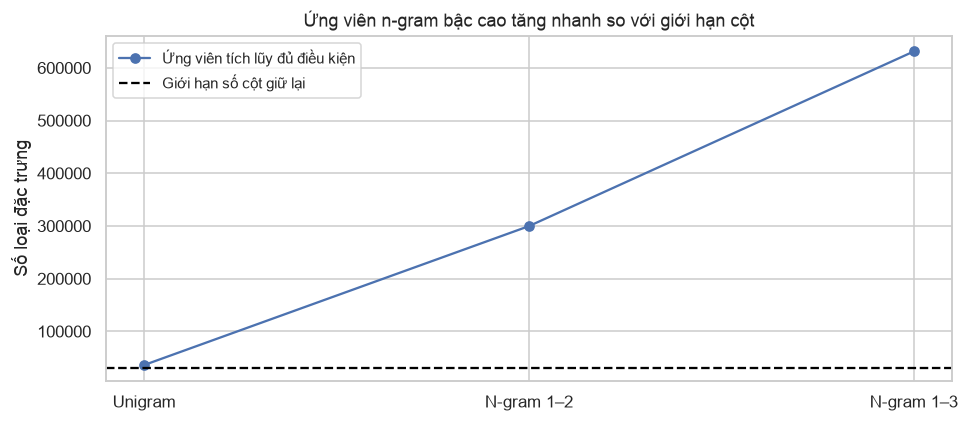

*Số ứng viên tăng khi thêm bigram và trigram. Giới hạn cột cố định làm các cụm từ cạnh tranh vị trí với unigram.*

In [4]:
vocabulary_growth=[]
for order in [1,2,3]:
    document_frequency=Counter()
    for tokens in base_tokens:
        document_frequency.update(set(" ".join(tokens[i:i+order]) for i in range(len(tokens)-order+1)))
    vocabulary_growth.append({"order":order,"observed_types":len(document_frequency),
                              "eligible_min_df_2":sum(count>=MIN_DF for count in document_frequency.values())})
    del document_frequency
vocabulary_growth=pd.DataFrame(vocabulary_growth)
vocabulary_growth["cumulative_eligible"]=vocabulary_growth.eligible_min_df_2.cumsum()
representations={};feature_records=[];representation_times={}
for method,(tfidf,max_n) in SPARSE_CONFIGS.items():
    started=perf_counter()
    vectorizer=word_vectorizer(tfidf=tfidf,max_n=max_n,max_features=MAX_FEATURES,min_df=MIN_DF)
    matrix=vectorizer.fit_transform(input_text).tocsr()
    names=vectorizer.get_feature_names_out()
    representations[method]=matrix
    eligible=int(vocabulary_growth.loc[vocabulary_growth.order.le(max_n),"eligible_min_df_2"].sum())
    feature_records.append({"method":method,"features":len(names),"eligible_candidates":eligible,
        "eligible_retained_pct":100*len(names)/eligible,"cap_reached":len(names)==MAX_FEATURES,
        "unigram_features":sum(" " not in name for name in names),
        "bigram_features":sum(name.count(" ")==1 for name in names),
        "trigram_features":sum(name.count(" ")==2 for name in names),
        "distinct_component_words":len(set(word for name in names for word in name.split()))})
    representation_times[method]=perf_counter()-started
    del vectorizer
feature_table=pd.DataFrame(feature_records).set_index("method")
show_table(vocabulary_growth,"Số ứng viên theo bậc trước khi áp giới hạn cột",index=False)
show_table(feature_table[["features","eligible_candidates","eligible_retained_pct","cap_reached"]].round(3),
           "Tác động của giới hạn cột")
show_table(feature_table[["unigram_features","bigram_features","trigram_features","distinct_component_words"]],
           "Số đặc trưng được giữ theo bậc n-gram")
assert feature_table.loc['TF-IDF 1-2','bigram_features']>0 and feature_table.loc['TF-IDF 1-3','trigram_features']>0
fig,ax=plt.subplots(figsize=(9,4))
ax.plot([1,2,3],vocabulary_growth.cumulative_eligible,marker="o",label="Ứng viên tích lũy đủ điều kiện")
ax.axhline(MAX_FEATURES,color="black",linestyle="--",label="Giới hạn số cột giữ lại")
ax.set_xticks([1,2,3],["Unigram","N-gram 1–2","N-gram 1–3"])
ax.set(ylabel="Số loại đặc trưng",title="Ứng viên n-gram bậc cao tăng nhanh so với giới hạn cột")
ax.legend(fontsize=10);plt.tight_layout();show_figure(fig, "Số ứng viên tăng khi thêm bigram và trigram. Giới hạn cột cố định làm các cụm từ cạnh tranh vị trí với unigram.")
display_report(prose((
                 f"Số ứng viên tích lũy tăng từ **{int(vocabulary_growth.iloc[0].cumulative_eligible):,}** "
                 f"lên **{int(vocabulary_growth.iloc[-1].cumulative_eligible):,}**. "
                 f"Ma trận có tối đa **{MAX_FEATURES:,}** cột nên các n-gram thường gặp cạnh tranh với unigram."
                 )))

### 2. Word2Vec khớp trên tập huấn luyện

CBOW dự đoán từ giữa từ trung bình vector lân cận. Skip-gram làm ngược chiều, dự đoán từ lân cận từ token ở giữa. Chọn CBOW cho thiết lập CPU cố định. Lấy mẫu âm tăng điểm cho cặp đúng và giảm điểm cho các từ âm.

$$
\log\sigma(u_w^T\bar v_C)+\sum_{k=1}^{5}\mathbb E_{n\sim P_n}
\log\sigma(-u_n^T\bar v_C).
$$

Dùng vector_size = 100, window = 5, min_count = 2, negative = 5, sample = 1e−3, 10 epoch, workers = 1, seed 42 và hàm băm khởi tạo CRC32 ổn định. Cửa sổ nằm trong từng mô tả và không dùng nhãn. Vector văn bản lấy trung bình mỗi lượt token có trong từ vựng.

$$z_d=\frac1{|K_d|}\sum_{w\in K_d}v_w.$$

Các lần lặp đóng góp theo tần suất. Bỏ token OOV khi lấy trung bình, trả vector 0 nếu mọi token đều OOV. Cách gộp thu được vector đặc ngắn nhưng mất trật tự, nhập các nghĩa theo ngữ cảnh và có thể đặt trọng số lớn cho từ thường gặp. `min_count` đếm lượt token, còn `min_df` đếm văn bản.

Bản Gensim 4.4.0 từ PyPI có thể trả 0 khi tích vô hướng đúng là −1. Đồ án ghim commit `ecf22c266f3b8930610114c149d8991ed14e2a16` để sửa khai báo `noexcept` của hai con trỏ hàm BLAS. Cài từ nguồn cần trình biên dịch C. Trước khi huấn luyện, kiểm tra tính đối xứng điểm hierarchical softmax cho CBOW và Skip-gram ở hai kích thước vector. Kết quả công bố dùng bản sửa đã kiểm chứng. [Lỗi upstream #3665](https://github.com/piskvorky/gensim/issues/3665) · [Bản sửa PR #3668](https://github.com/piskvorky/gensim/pull/3668)


In [5]:
started=perf_counter()
# Explicit build/train also verifies updates rather than accepting initialized embeddings.
w2v_numeric_check=word2vec_numeric_guard()
gensim_source=json.loads(distribution('gensim').read_text('direct_url.json'))
assert gensim_source['vcs_info']['commit_id']=='ecf22c266f3b8930610114c149d8991ed14e2a16'
with threadpool_limits(limits=2):
    w2v_model=Word2Vec(**W2V_PARAMETERS)
    w2v_model.build_vocab(base_tokens.tolist())
    initialized_vectors=w2v_model.wv.vectors.copy()
    trained_effective_words,trained_raw_words=w2v_model.train(base_tokens.tolist(),
        total_examples=len(base_tokens),epochs=W2V_PARAMETERS['epochs'],compute_loss=True)
    training_update_norm=float(np.linalg.norm(w2v_model.wv.vectors-initialized_vectors))
    del initialized_vectors
    assert np.isfinite(w2v_model.wv.vectors).all() and training_update_norm>0
    assert np.isfinite(w2v_model.get_latest_training_loss())
    w2v_vectors,w2v_coverage=mean_word_vectors(base_tokens.tolist(),w2v_model.wv)
assert trained_raw_words==sum(map(len,base_tokens))*W2V_PARAMETERS['epochs']
assert np.isfinite(w2v_vectors).all()
representation_times["Word2Vec"]=perf_counter()-started
representations["Word2Vec"]=w2v_vectors
w2v_vocabulary=len(w2v_model.wv)
w2v_report=pd.Series({"algorithm":"CBOW, negative sampling","documents_fit":len(train),
    "learned_word_vocabulary":w2v_vocabulary,"vector_size":w2v_model.vector_size,
    "window":5,"min_count":2,"negative":5,"epochs":10,"workers":1,"seed":42,
    "stable_hash":"CRC32","weight_update_L2":training_update_norm,
    "effective_training_words":trained_effective_words,"raw_training_words":trained_raw_words,
    "finite_training_loss":bool(np.isfinite(w2v_model.get_latest_training_loss())),
    "BLAS_regression_cases_passed":w2v_numeric_check['passed_cases'],
    "BLAS_regression_max_error":w2v_numeric_check['max_symmetry_error'],
    "gensim_source_commit":gensim_source['vcs_info']['commit_id'],"seconds_fit_and_pool":representation_times["Word2Vec"],**w2v_coverage},name="observed")
show_table(w2v_report.to_frame(),"Thiết lập học Word2Vec và cách gộp vector")
display_report(prose((
                 f"Word2Vec học **{w2v_vocabulary:,}** loại token và tạo vector trung bình **{w2v_vectors.shape[1]}** chiều cho mỗi mô tả. "
                 f"Trong tập huấn luyện, OOV theo lượt là **{w2v_coverage['OOV_rate']:.3%}** và có **{w2v_coverage['zero_documents']}** văn bản nhận vector 0."
                 )))

,Giá trị quan sát
algorithm,"CBOW, negative sampling"
documents_fit,22201
learned_word_vocabulary,40880
vector_size,100
window,5
min_count,2
negative,5
epochs,10
workers,1
seed,42


### 3. MiniLM đóng băng và độ dài đầu vào

Dùng trọng số công khai `all-MiniLM-L6-v2` theo commit cố định ở bảng. Mô hình 384 chiều dùng token con của bộ mã hóa và trung bình có mặt nạ chú ý để tạo embedding văn bản, sau đó chuẩn L2. Đo độ dài với chính bộ tách của mô hình, trước khi cắt, kể cả token đặc biệt. Báo số dòng vượt giới hạn mô hình để đánh giá khả năng mất nội dung cuối mô tả. Mô hình chạy CPU, giữ trọng số công khai và xử lý cùng dạng văn bản như các phương án khác. [Thẻ mô hình](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)


In [6]:
started=perf_counter()
try:
    snapshot=snapshot_download(MODEL_NAME,revision=MODEL_REVISION,cache_dir=str(MODEL_CACHE),
                               allow_patterns=MODEL_FILES,token=False,local_files_only=True)
    model_preparation="exact local model revision reused"
except Exception:
    try:
        snapshot=snapshot_download(MODEL_NAME,revision=MODEL_REVISION,cache_dir=str(MODEL_CACHE),
                                   allow_patterns=MODEL_FILES,token=False)
        model_preparation="downloaded public model revision once"
    except Exception:
        raise RuntimeError("Cannot obtain sentence-transformers/all-MiniLM-L6-v2 at revision "+MODEL_REVISION+
            ". Check network access to huggingface.co and install the pinned lock, then rerun. "
            "Weights are stored under .cache/huggingface; no substitute embeddings are generated.") from None
encoder=SentenceTransformer(snapshot,device="cpu",local_files_only=True,trust_remote_code=False)
encoder.eval();encoder.requires_grad_(False)
assert not any(parameter.requires_grad for parameter in encoder.parameters())
assert encoder.get_embedding_dimension()==384
max_sequence_length=int(encoder.max_seq_length)
model_load_seconds=perf_counter()-started
subword_lengths=[]
for offset in range(0,len(input_text),256):
    batch=input_text.iloc[offset:offset+256].tolist()
    lengths=encoder.tokenizer(batch,add_special_tokens=True,truncation=False,return_length=True,verbose=False)["length"]
    subword_lengths.extend(lengths)
subword_lengths=np.asarray(subword_lengths)
truncation_report=pd.Series({"model_max_seq_length":max_sequence_length,
    "TRAIN_subword_mean":subword_lengths.mean(),"TRAIN_subword_median":np.median(subword_lengths),
    "TRAIN_subword_P95":np.quantile(subword_lengths,.95),"TRAIN_subword_max":subword_lengths.max(),
    "documents_over_model_limit":int((subword_lengths>max_sequence_length).sum()),
    "pct_over_model_limit":100*(subword_lengths>max_sequence_length).mean()},name="measured")
started=perf_counter()
minilm_vectors=frozen_sentence_vectors(encoder,input_text.tolist(),batch_size=32)
representation_times["MiniLM"]=perf_counter()-started
assert minilm_vectors.shape==(len(train),384) and np.isfinite(minilm_vectors).all()
representations["MiniLM"]=minilm_vectors
model_provenance=pd.Series({"name":MODEL_NAME,"revision":MODEL_REVISION,"output_dimensions":minilm_vectors.shape[1],
    "pretrained_subword_vocab":encoder.tokenizer.vocab_size,"device":str(encoder.device),"dtype":str(minilm_vectors.dtype),
    "batch_size":32,"normalize_embeddings":True,"fine_tuned":False,
    "load_seconds":model_load_seconds,"encode_seconds":representation_times["MiniLM"],
    "weights_SHA256":hashlib.sha256((Path(snapshot)/"model.safetensors").read_bytes()).hexdigest()},name="observed")
print(model_preparation)
show_table(model_provenance.to_frame(),"Cấu hình và nguồn của mô hình",collapse=True)
show_table(truncation_report.to_frame().round(3),"Số văn bản vượt giới hạn đầu vào MiniLM")
display_report(prose((
                 f"MiniLM tạo ma trận **{minilm_vectors.shape}** trong **{representation_times['MiniLM']:.1f} giây** trên CPU. "
                 f"**{int(truncation_report.documents_over_model_limit):,}** mô tả huấn luyện "
                 f"(**{truncation_report.pct_over_model_limit:.2f}%**) dài hơn giới hạn **{max_sequence_length}** token con, nên phần cuối bị cắt."
                 )))

exact local model revision reused


,Giá trị quan sát
name,sentence-transformers/all-MiniLM-L6-v2
revision,1110a243fdf4706b3f48f1d95db1a4f5529b4d41
output_dimensions,384
pretrained_subword_vocab,30522
device,cpu
dtype,float32
batch_size,32
normalize_embeddings,True
fine_tuned,False
load_seconds,0.268596


,Giá trị đo
model_max_seq_length,256.000
TRAIN_subword_mean,134.286
TRAIN_subword_median,93.000
TRAIN_subword_P95,358.000
TRAIN_subword_max,9137.000
documents_over_model_limit,2863.000
pct_over_model_limit,12.896


### 4. Số chiều, độ thưa, dung lượng và vector 0

$$\mathrm{sparsity}=1-\frac{nnz}{N D}.$$

Đếm phần tử khác 0 về giá trị. Dung lượng CSR là tổng bộ đệm data, indices và indptr. Với ma trận đặc dùng `nbytes`. Các phép đo bỏ qua mô hình và đối tượng Python. Dung lượng đặc tương đương được tính từ kích thước và kiểu dữ liệu. Vector Word2Vec toàn 0 xuất hiện khi không có token trong từ vựng. Các biểu diễn vẫn giữ đủ dòng.


In [7]:
profile_rows=[]
for method,matrix in representations.items():
    report=matrix_profile(matrix)
    if method in SPARSE_CONFIGS:
        words=int(feature_table.loc[method,"distinct_component_words"])
        source="TRAIN fitted features"
    elif method=="Word2Vec": words=w2v_vocabulary;source="TRAIN learned words"
    else: words=None;source="external pretrained subwords"
    profile_rows.append({"method":method,**report,"learned_component_words":words,"vocab_source":source,
                         "shape":str(matrix.shape),"construction_seconds":representation_times[method]})
representation_table=pd.DataFrame(profile_rows).set_index("method")
show_table(representation_table[["documents","dimensions","nnz","sparsity","zero_documents"]].round(6),
           "Kích thước và độ thưa của vector huấn luyện")
show_table(pd.DataFrame({"Layout":representation_table.layout,
    "Stored MiB":representation_table.storage_bytes/1024**2,
    "Dense equivalent MiB":representation_table.dense_equivalent_bytes/1024**2,
    "Build / encode seconds":representation_table.construction_seconds}).round(3),"Dung lượng vector và thời gian chạy")
show_table(representation_table[["shape","learned_component_words","vocab_source"]],"Đơn vị từ vựng của từng biểu diễn",collapse=True)
assert all(matrix.shape[0]==len(train) for matrix in representations.values())

,Số văn bản,Số chiều,nnz,Độ thưa,Số văn bản có vector 0
Phương pháp,,,,,
BoW,22201,30000,1550936,0.997671,4
TF-IDF 1,22201,30000,1550936,0.997671,4
TF-IDF 1-2,22201,30000,2341334,0.996485,20
TF-IDF 1-3,22201,30000,2476413,0.996282,26
Word2Vec,22201,100,2220000,0.000045,1
MiniLM,22201,384,8525184,0.000000,0


,Layout,Dung lượng (MiB),Tương đương dạng đặc (MiB),Tạo và mã hóa (giây)
Phương pháp,,,,
BoW,CSR,17.834,5081.406,0.645
TF-IDF 1,CSR,17.834,5081.406,0.669
TF-IDF 1-2,CSR,26.879,5081.406,3.487
TF-IDF 1-3,CSR,28.425,5081.406,8.840
Word2Vec,dense,8.469,8.469,33.642
MiniLM,dense,32.521,32.521,206.941


,Kích thước,learned_component_words,Nguồn từ vựng
Phương pháp,,,
BoW,"(22201, 30000)",30000.0,TRAIN fitted features
TF-IDF 1,"(22201, 30000)",30000.0,TRAIN fitted features
TF-IDF 1-2,"(22201, 30000)",10807.0,TRAIN fitted features
TF-IDF 1-3,"(22201, 30000)",9667.0,TRAIN fitted features
Word2Vec,"(22201, 100)",40880.0,TRAIN learned words
MiniLM,"(22201, 384)",NaN,external pretrained subwords


### 5. Cosine của cặp cùng và khác danh mục

$$\cos(x_i,x_j)=\frac{x_i^T x_j}{\|x_i\|_2\|x_j\|_2}.$$

Nhân theo đúng cặp trên các vector đã chuẩn hóa. Hạn ngạch cân bằng từng lớp và từng cặp lớp. Nhãn chỉ dùng để chọn cặp mô tả. Báo trung bình, trung vị, IQR và chênh lệch trung bình. Độ lớn cosine giữa các biểu diễn phụ thuộc cách tọa độ mã hóa nội dung.


,Trung bình khác lớp,Trung bình cùng lớp,Trung vị khác lớp,Trung vị cùng lớp,Chênh lệch trung bình cùng − khác lớp
Phương pháp,,,,,
BoW,0.15051,0.18371,0.12237,0.15090,0.03320
TF-IDF 1,0.02075,0.03547,0.01609,0.02850,0.01473
TF-IDF 1-2,0.01496,0.02707,0.01103,0.02070,0.01211
TF-IDF 1-3,0.01455,0.02666,0.01070,0.01984,0.01211
Word2Vec,0.34296,0.55810,0.35124,0.59464,0.21514
MiniLM,0.08312,0.19660,0.07457,0.18686,0.11348


Phương pháp,Loại cặp,Số cặp,Trung bình,Trung vị,Q1,Q3,SD,Số cặp có vector 0
BoW,same,2400,0.183708,0.150904,0.051427,0.275221,0.160981,2
BoW,different,2400,0.150513,0.122375,0.032209,0.240825,0.136726,2
TF-IDF 1,same,2400,0.035473,0.028503,0.008137,0.051915,0.035300,2
TF-IDF 1,different,2400,0.020746,0.016093,0.003963,0.032378,0.020092,2
TF-IDF 1-2,same,2400,0.027072,0.020698,0.005902,0.038883,0.030564,5
TF-IDF 1-2,different,2400,0.014963,0.011027,0.002913,0.022744,0.015169,8
TF-IDF 1-3,same,2400,0.026660,0.019837,0.005831,0.037904,0.031162,8
TF-IDF 1-3,different,2400,0.014551,0.010705,0.002871,0.021770,0.015065,8
Word2Vec,same,2400,0.558102,0.594638,0.425549,0.726573,0.219523,1
Word2Vec,different,2400,0.342959,0.351245,0.155712,0.542785,0.251551,1


SHA-256 của mã cặp bc1f399d8ef08c6706f756bc9be9a2e0cb974d50b6b3132788e6bf5528341026


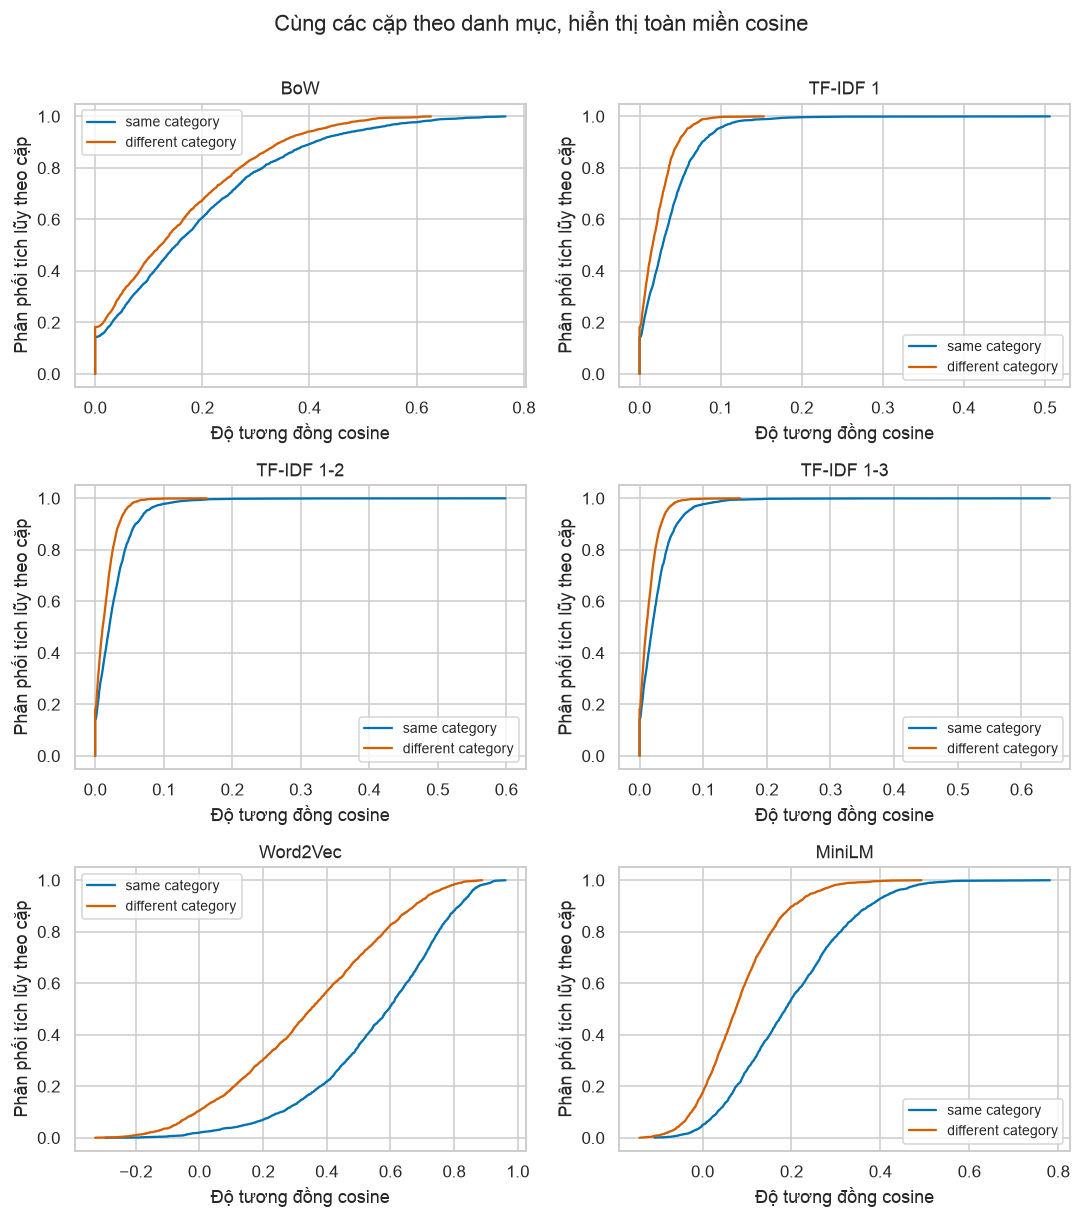

*Phân phối tích lũy cosine của cùng các cặp. Khoảng cách giữa đường cùng lớp và khác lớp lớn nhất với trung bình Word2Vec.*

In [8]:
pair_table=sample_document_pairs(y,same_per_class=600,different_per_class_pair=400,seed=PAIR_SEED)
pair_indices=pair_table[["i","j"]].to_numpy()
assert not np.any(pair_indices[:,0]==pair_indices[:,1])
assert not pair_table[["i","j"]].duplicated().any()
pair_ID_hash=hashlib.sha256(train.row_id.to_numpy()[pair_indices].astype("<i8").tobytes()).hexdigest()
show_table(pair_table.groupby(["same_class","class_a","class_b"]).size().rename("pairs").to_frame(),
           "Số cặp cố định theo lớp và cặp lớp",collapse=True)
cosine_records=[];similarity_values={}
for method,matrix in representations.items():
    values=paired_cosines(matrix,pair_indices)
    similarity_values[method]=values
    norms=row_norms(matrix)
    for same in [True,False]:
        mask=pair_table.same_class.to_numpy()==same
        selected=values[mask]
        zero_pairs=np.any(norms[pair_indices[mask]]==0,axis=1).sum()
        cosine_records.append({"method":method,"pair_type":"same" if same else "different","pairs":len(selected),
            "mean":selected.mean(),"median":np.median(selected),"Q1":np.quantile(selected,.25),
            "Q3":np.quantile(selected,.75),"SD":selected.std(ddof=1),"zero_vector_pairs":int(zero_pairs)})
cosine_table=pd.DataFrame(cosine_records)
cosine_summary=cosine_table.pivot(index="method",columns="pair_type",values=["mean","median"]).reindex(representations)
cosine_summary.columns=[f"{metric}_{kind}" for metric,kind in cosine_summary.columns]
cosine_summary["mean_same_minus_different"]=cosine_summary.mean_same-cosine_summary.mean_different
show_table(cosine_summary.round(5),"Thống kê cosine trên cùng các cặp huấn luyện")
show_table(cosine_table.round(6),"Số cặp, tứ phân vị, độ lệch chuẩn và số cặp có vector 0",collapse=True,index=False)
print("SHA-256 của mã cặp",pair_ID_hash)
fig,axes=plt.subplots(3,2,figsize=(10,11))
for ax,(method,values) in zip(axes.flat,similarity_values.items()):
    for same,label,color in [(True,"same category","#0072B2"),(False,"different category","#D55E00")]:
        selected=values[pair_table.same_class.to_numpy()==same]
        selected=np.sort(selected)
        ax.plot(selected,np.arange(1,len(selected)+1)/len(selected),label=label,color=color)
    ax.set(title=method,xlabel="Độ tương đồng cosine",ylabel="Phân phối tích lũy theo cặp")
    ax.legend(fontsize=9)
fig.suptitle("Cùng các cặp theo danh mục, hiển thị toàn miền cosine",y=1.005)
plt.tight_layout();show_figure(fig, "Phân phối tích lũy cosine của cùng các cặp. Khoảng cách giữa đường cùng lớp và khác lớp lớn nhất với trung bình Word2Vec.")
largest_gap=cosine_summary.mean_same_minus_different.idxmax()
display_report(prose((
                 f"Chênh lệch trung bình cosine cùng lớp và khác lớp lớn nhất thuộc về **{largest_gap}** "
                 f"(**{cosine_summary.loc[largest_gap,'mean_same_minus_different']:.4f}**). "
                 "Giá trị này mô tả các cặp được chọn theo hạn ngạch cân bằng."
                 )))

### 6. Silhouette theo nhãn thật và theo cụm K-Means

Với điểm $i$, $a_i$ là khoảng cách trung bình tới nhóm của nó, $b_i$ là khoảng cách trung bình nhỏ nhất tới một nhóm khác.

$$s_i=\frac{b_i-a_i}{\max(a_i,b_i)},\qquad S=\frac1N\sum_i s_i.$$

Silhouette theo nhãn thật đo mức tách của danh mục trong không gian gốc. Silhouette theo cụm đo mức kết dính của các nhóm tìm được. Cùng dùng cosine trên vector đơn vị, kèm kết quả Euclid. Cụm kết dính vẫn có thể khác phân loại sản phẩm, nên xem cùng ARI và số điểm mỗi cụm.

Dùng cùng tập con cân bằng và giao vector khác 0 của mọi biểu diễn. Khi số nhãn hoặc vector không phù hợp, trả trạng thái và NaN. So sánh nâng cao tập trung vào TF-IDF unigram và MiniLM, với các biểu diễn còn lại để đối chiếu.


In [9]:
candidate_subset=balanced_subset(y,per_class=PER_CLASS,seed=SUBSET_SEED)
common_nonzero=np.ones(len(candidate_subset),dtype=bool)
for matrix in representations.values(): common_nonzero &= row_norms(matrix[candidate_subset])>0
geometry_indices=candidate_subset[common_nonzero]
geometry_labels=y[geometry_indices]
geometry_ID_hash=hashlib.sha256(train.iloc[geometry_indices].row_id.to_numpy(dtype="<i8").tobytes()).hexdigest()
geometry_support=pd.Series(geometry_labels).value_counts().reindex(LABELS).rename("geometry_N").to_frame()
show_table(geometry_support,"Tập con chung có vector khác 0 ở cả sáu biểu diễn")
print("Số dòng ứng viên",len(candidate_subset),"| common nonzero N:",len(geometry_indices),
      "| exclusions from every geometry:",int((~common_nonzero).sum()))
print("SHA-256 của mã dòng trong tập con",geometry_ID_hash)
geometry_matrices={method:normalize(matrix[geometry_indices],norm="l2",copy=True)
                   for method,matrix in representations.items()}
geometry_rows=[];cluster_rows=[];cluster_assignments={};geometry_warning_records=[]
with threadpool_limits(limits=2):
    for method,matrix in geometry_matrices.items():
        started=perf_counter()
        clustering=KMeans(n_clusters=4,init="k-means++",n_init=10,max_iter=300,
                          random_state=42,algorithm="lloyd")
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            labels=clustering.fit_predict(matrix)
        for warning in caught:
            geometry_warning_records.append({"method":method,"category":warning.category.__name__,"message":str(warning.message)})
            warnings.warn(str(warning.message),warning.category)
        cluster_assignments[method]=labels
        row={"method":method,"N":len(labels),"ARI":adjusted_rand_score(geometry_labels,labels)}
        for metric in ["cosine","euclidean"]:
            for label_name,group_labels in [("true",geometry_labels),("cluster",labels)]:
                value,status=safe_silhouette(matrix,group_labels,metric=metric)
                row[f"{label_name}_{metric}"]=value
                row[f"{label_name}_{metric}_status"]=status
        row["seconds"]=perf_counter()-started
        geometry_rows.append(row)
        cluster_rows.append({"method":method,**{f"cluster_{k}":int((labels==k).sum()) for k in range(4)}})
geometry_table=pd.DataFrame(geometry_rows).set_index("method")
cluster_sizes=pd.DataFrame(cluster_rows).set_index("method")
show_table(geometry_table[["true_cosine","cluster_cosine","ARI"]].round(5),
           "Mức tách theo nhãn và theo cụm trong không gian gốc")
show_table(cluster_sizes,"Cỡ của bốn cụm, đánh số theo K-Means")
show_table(geometry_table[["true_euclidean","cluster_euclidean","seconds"]].round(5),
           "Đối chiếu khi dùng khoảng cách Euclid")
show_table(geometry_table.filter(like="status"),"Điều kiện tính silhouette",collapse=True)
show_table(pd.DataFrame(geometry_warning_records,columns=["method","category","message"]),"Cảnh báo khi phân cụm",collapse=True,index=False)
advanced_geometry=geometry_table.loc[["TF-IDF 1","MiniLM"],["true_cosine","cluster_cosine","ARI"]]
show_table(advanced_geometry.round(6),"So sánh K-Means giữa TF-IDF và Sentence Transformer")
display_report(prose((
                 f"Silhouette cosine theo nhãn thật và theo cụm lần lượt là "
                 f"**{geometry_table.loc['TF-IDF 1','true_cosine']:.4f} / {geometry_table.loc['TF-IDF 1','cluster_cosine']:.4f}** với TF-IDF unigram "
                 f"và **{geometry_table.loc['MiniLM','true_cosine']:.4f} / {geometry_table.loc['MiniLM','cluster_cosine']:.4f}** với MiniLM. "
                 "Cỡ cụm và ARI giúp đối chiếu cụm tìm được với danh mục sản phẩm."
                 )))

,geometry_N
Household,300
Books,300
Clothing & Accessories,300
Electronics,300


Số dòng ứng viên 1200 | common nonzero N: 1200 | exclusions from every geometry: 0
SHA-256 của mã dòng trong tập con 2c624ece21bf96955527d1742bcf996f548a6969360be4d5e4a57aab88ca9fa2


,Silhouette cosine theo nhãn,Silhouette cosine theo cụm,ARI
Phương pháp,,,
BoW,0.01260,0.00815,0.09914
TF-IDF 1,0.01125,0.01190,0.32645
TF-IDF 1-2,0.00940,0.01043,0.35440
TF-IDF 1-3,0.00936,0.01031,0.11458
Word2Vec,0.18767,0.27045,0.41370
MiniLM,0.08572,0.10477,0.72719


,cluster_0,cluster_1,cluster_2,cluster_3
Phương pháp,,,,
BoW,264,377,321,238
TF-IDF 1,337,441,245,177
TF-IDF 1-2,268,511,251,170
TF-IDF 1-3,9,103,169,919
Word2Vec,247,252,423,278
MiniLM,291,319,314,276


,Silhouette Euclid theo nhãn,Silhouette Euclid theo cụm,Thời gian (giây)
Phương pháp,,,
BoW,0.00737,0.00545,0.33355
TF-IDF 1,0.00583,0.00616,0.24892
TF-IDF 1-2,0.00488,0.00542,0.30752
TF-IDF 1-3,0.00487,0.00598,0.29974
Word2Vec,0.11050,0.15743,0.11644
MiniLM,0.04590,0.05602,0.22136


,true_cosine_status,cluster_cosine_status,true_euclidean_status,cluster_euclidean_status
Phương pháp,,,,
BoW,ok,ok,ok,ok
TF-IDF 1,ok,ok,ok,ok
TF-IDF 1-2,ok,ok,ok,ok
TF-IDF 1-3,ok,ok,ok,ok
Word2Vec,ok,ok,ok,ok
MiniLM,ok,ok,ok,ok


Phương pháp,Mức,message


,Silhouette cosine theo nhãn,Silhouette cosine theo cụm,ARI
Phương pháp,,,
TF-IDF 1,0.011249,0.011899,0.326454
MiniLM,0.085719,0.104771,0.727192


### 7. Trực quan hóa SVD và t-SNE trên cùng tập con

Khớp TruncatedSVD 50 thành phần cho từng biểu diễn, chỉ trên tập con chung. Báo tỷ lệ phương sai rồi chuẩn L2 và khớp t-SNE. SVD ở đây không quy tâm. Tọa độ mỗi hình có thang và hướng riêng. Khoảng cách nhìn thấy giữa các cụm có thể khác không gian gốc. Silhouette và phân loại dùng vector gốc.


,N,SVD_components,SVD_explained_variance_sum,perplexity,tSNE_iterations,KL_divergence,Thời gian (giây)
Phương pháp,,,,,,,
BoW,1200,50,0.35773,30,999,1.57951,4.09762
TF-IDF 1,1200,50,0.14281,30,999,1.09250,4.22062
TF-IDF 1-2,1200,50,0.12782,30,999,1.09078,4.69811
TF-IDF 1-3,1200,50,0.12852,30,999,1.10303,4.71592
Word2Vec,1200,50,0.94882,30,999,1.06120,3.77615
MiniLM,1200,50,0.57582,30,999,1.11359,3.52560


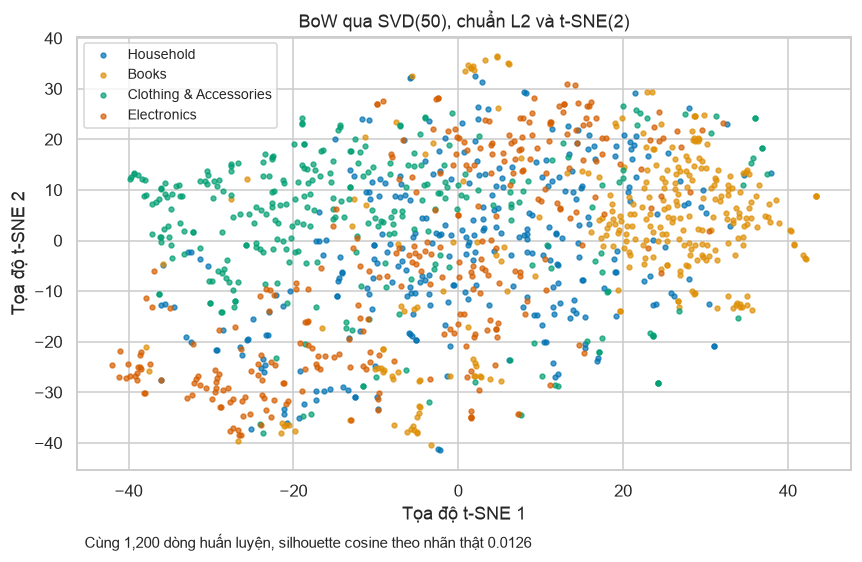

*Chiếu t-SNE của BoW trên cùng tập con huấn luyện. Các nhãn có vùng tập trung và vùng chồng lấn. Silhouette được tính riêng từ không gian gốc.*

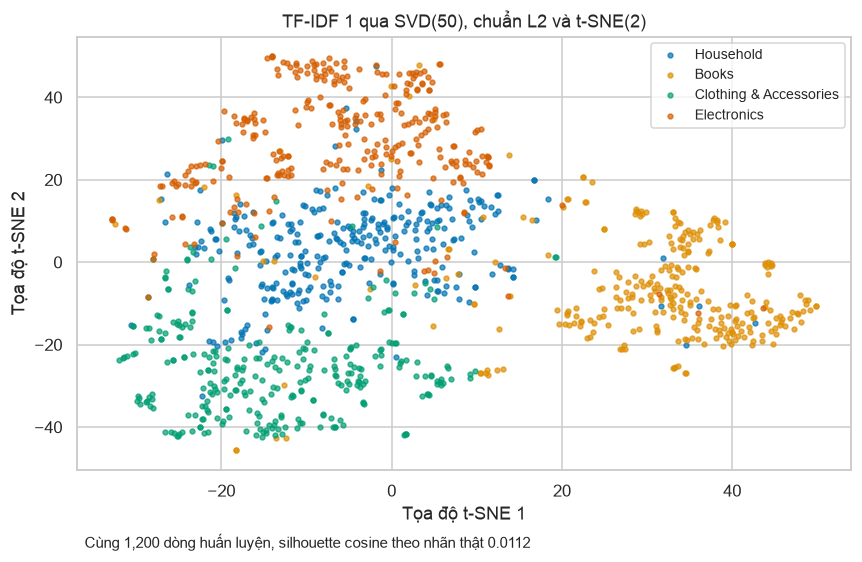

*Chiếu t-SNE của TF-IDF 1 trên cùng tập con huấn luyện. Các nhãn có vùng tập trung và vùng chồng lấn. Silhouette được tính riêng từ không gian gốc.*

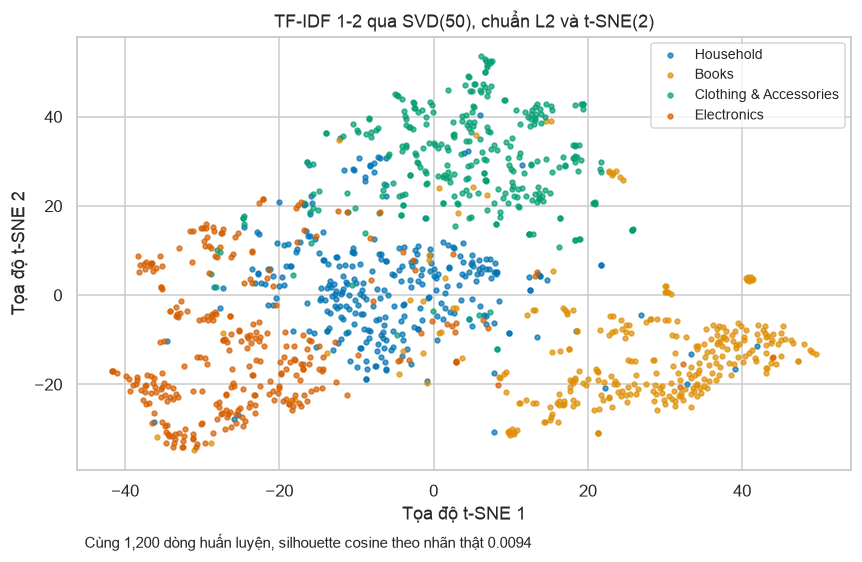

*Chiếu t-SNE của TF-IDF 1-2 trên cùng tập con huấn luyện. Các nhãn có vùng tập trung và vùng chồng lấn. Silhouette được tính riêng từ không gian gốc.*

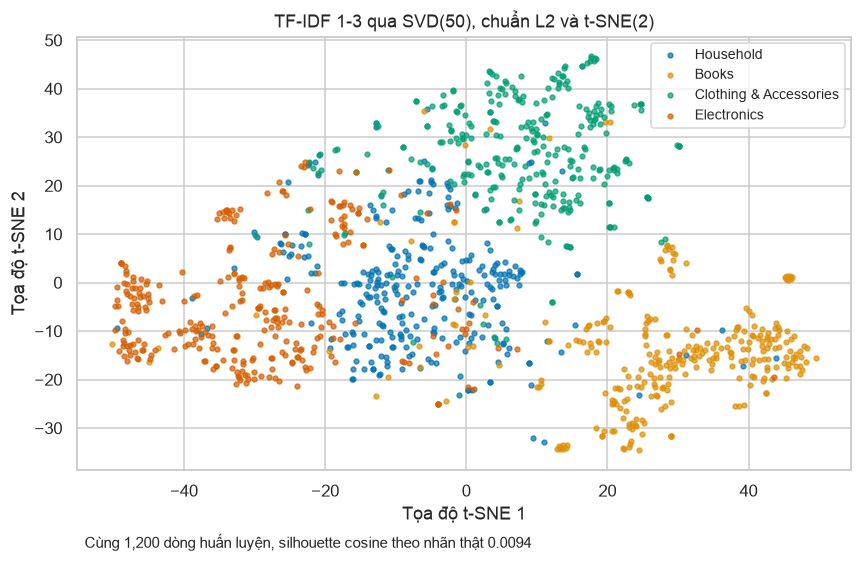

*Chiếu t-SNE của TF-IDF 1-3 trên cùng tập con huấn luyện. Các nhãn có vùng tập trung và vùng chồng lấn. Silhouette được tính riêng từ không gian gốc.*

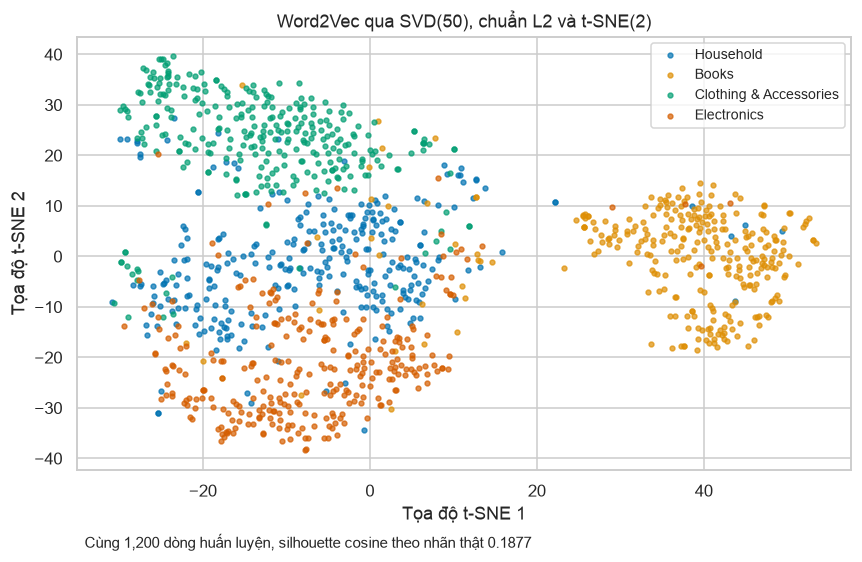

*Chiếu t-SNE của Word2Vec trên cùng tập con huấn luyện. Các nhãn có vùng tập trung và vùng chồng lấn. Silhouette được tính riêng từ không gian gốc.*

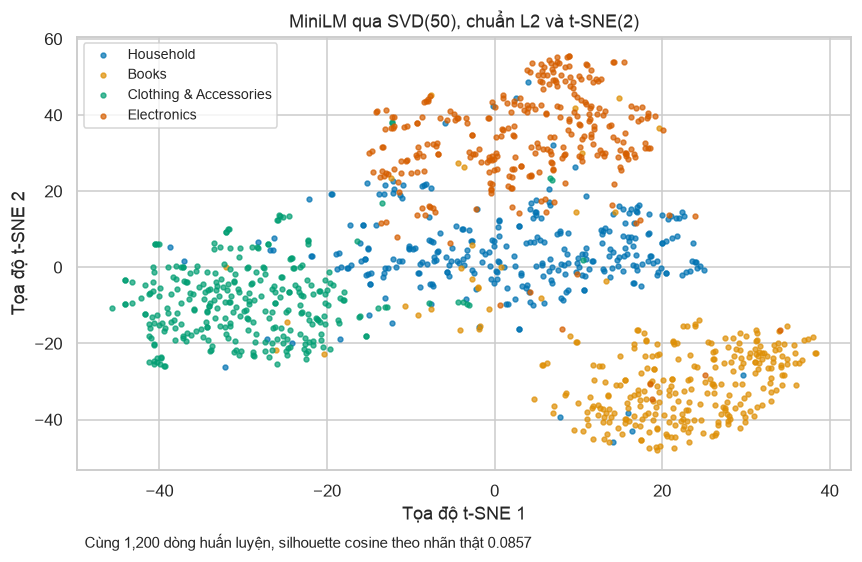

*Chiếu t-SNE của MiniLM trên cùng tập con huấn luyện. Các nhãn có vùng tập trung và vùng chồng lấn. Silhouette được tính riêng từ không gian gốc.*

In [10]:
tsne_coordinates={};reduction_rows=[]
with threadpool_limits(limits=2):
    for method,matrix in geometry_matrices.items():
        started=perf_counter()
        svd=TruncatedSVD(n_components=50,n_iter=7,random_state=42)
        reduced=normalize(svd.fit_transform(matrix),norm="l2")
        projection=TSNE(n_components=2,perplexity=30,learning_rate="auto",init="pca",metric="euclidean",
                         max_iter=1000,random_state=42,method="barnes_hut",n_jobs=2)
        coords=projection.fit_transform(reduced)
        tsne_coordinates[method]=coords
        reduction_rows.append({"method":method,"N":len(coords),"SVD_components":50,
            "SVD_explained_variance_sum":svd.explained_variance_ratio_.sum(),
            "perplexity":30,"tSNE_iterations":projection.n_iter_,"KL_divergence":projection.kl_divergence_,
            "seconds":perf_counter()-started})
reduction_table=pd.DataFrame(reduction_rows).set_index("method")
show_table(reduction_table.round(5),"Tham số và kết quả kiểm tra giảm chiều",collapse=True)
# One large readable figure per representation; consistent color/category legend.
colors=dict(zip(LABELS,sns.color_palette("colorblind",4)))
for method,coords in tsne_coordinates.items():
    fig,ax=plt.subplots(figsize=(8,5.3))
    for label in LABELS:
        mask=geometry_labels==label
        ax.scatter(coords[mask,0],coords[mask,1],s=10,alpha=.7,label=label,color=colors[label])
    ax.set(title=f"{method} qua SVD(50), chuẩn L2 và t-SNE(2)",xlabel="Tọa độ t-SNE 1",ylabel="Tọa độ t-SNE 2")
    ax.legend(fontsize=9,loc="best")
    ax.text(.01,-.18,f"Cùng {len(geometry_indices):,} dòng huấn luyện, silhouette cosine theo nhãn thật "
            f"{geometry_table.loc[method,'true_cosine']:.4f}",transform=ax.transAxes,fontsize=10)
    plt.tight_layout();show_figure(fig, f"Chiếu t-SNE của {method} trên cùng tập con huấn luyện. Các nhãn có vùng tập trung và vùng chồng lấn. Silhouette được tính riêng từ không gian gốc.")

### 8. Linear SVM trên năm fold cố định

So BoW, ba dải TF-IDF và MiniLM với cùng LinearSVC, chuẩn L2 và thành viên từng fold. Với ma trận thưa, dựng lại pipeline theo thứ tự vector hóa, chuẩn L2 và SVM. Chỉ phần khớp xác định từ vựng và IDF. Với MiniLM, lấy các vector đã mã hóa cố định theo mã dòng và khớp SVM riêng. Phần Word2Vec mô tả dùng toàn tập huấn luyện nên không có điểm CV ở đây.

LinearSVC học ranh giới one-vs-rest cho bốn danh mục. C cố định tạo điều kiện đối chiếu, dù độ mạnh điều chuẩn phù hợp có thể khác nhau giữa không gian. Ghi cảnh báo hội tụ, F1-macro từng fold, độ lệch chuẩn mẫu, accuracy và chênh lệch theo fold.


,F1 trung bình,Độ lệch chuẩn mẫu,mean_accuracy,mean_dimensions
Phương pháp,,,,
BoW,0.953122,0.002549,0.953651,30000.0
TF-IDF 1,0.957556,0.001625,0.958200,30000.0
TF-IDF 1-2,0.955508,0.002414,0.955903,30000.0
TF-IDF 1-3,0.954285,0.002257,0.954732,30000.0
MiniLM,0.937778,0.003766,0.937930,384.0


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Phương pháp,,,,,
BoW,0.956760,0.951316,0.951976,0.954772,0.950785
TF-IDF 1,0.959642,0.956834,0.955410,0.957328,0.958569
TF-IDF 1-2,0.959653,0.953372,0.954524,0.954805,0.955189
TF-IDF 1-3,0.957987,0.952269,0.952828,0.953688,0.954655
MiniLM,0.942919,0.938813,0.933506,0.938965,0.934687


,Thời gian trung bình (giây),Số vòng lặp lớn nhất,Cảnh báo hội tụ
Phương pháp,,,
BoW,1.652,13,0
TF-IDF 1,1.384,12,0
TF-IDF 1-2,4.632,12,0
TF-IDF 1-3,9.878,13,0
MiniLM,2.224,8,0


Phương pháp,fold,macro_F1,accuracy,Số chiều sau khớp,Thời gian (giây),Số vòng lặp,Cảnh báo hội tụ
BoW,1,0.956760,0.957217,30000,1.660936,12,0
BoW,2,0.951316,0.951351,30000,1.503311,12,0
BoW,3,0.951976,0.952928,30000,1.951163,13,0
BoW,4,0.954772,0.955180,30000,1.606471,13,0
BoW,5,0.950785,0.951577,30000,1.538864,12,0
TF-IDF 1,1,0.959642,0.960594,30000,1.396801,11,0
TF-IDF 1,2,0.956834,0.957207,30000,1.313754,11,0
TF-IDF 1,3,0.955410,0.956306,30000,1.559314,12,0
TF-IDF 1,4,0.957328,0.957432,30000,1.394673,12,0
TF-IDF 1,5,0.958569,0.959459,30000,1.254529,11,0


Phương pháp,fold,Mức,message


Phương pháp,BoW,MiniLM,TF-IDF 1-2,TF-IDF 1-3
fold,,,,
1,-0.002882,-0.016723,0.000011,-0.001655
2,-0.005517,-0.018021,-0.003462,-0.004564
3,-0.003434,-0.021904,-0.000886,-0.002582
4,-0.002555,-0.018363,-0.002523,-0.003639
5,-0.007784,-0.023882,-0.003380,-0.003914


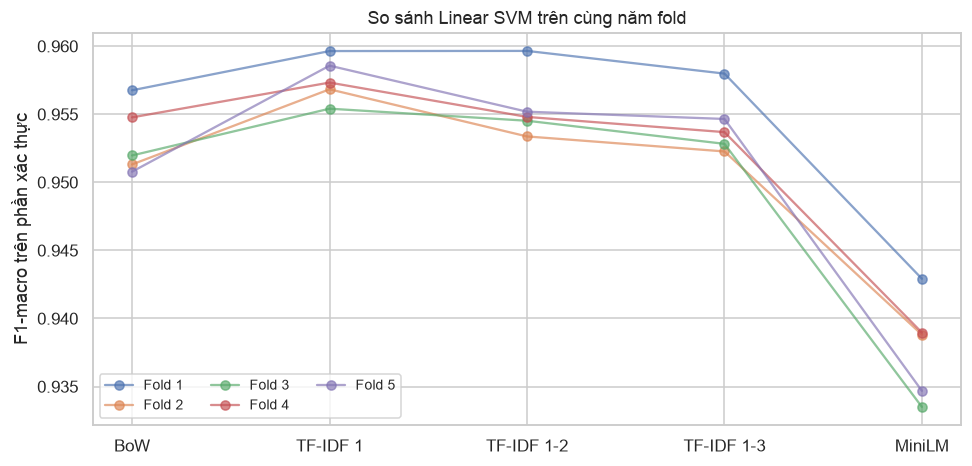

*Điểm Linear SVM theo fold. TF-IDF unigram có F1-macro trung bình cao nhất trong năm cấu hình.*

In [11]:
cv_records=[];cv_warning_records=[]
with threadpool_limits(limits=2):
    for method in [*SPARSE_CONFIGS,"MiniLM"]:
        for number,(fitting,validation) in enumerate(folds,1):
            started=perf_counter()
            if method=="MiniLM":
                estimator=linear_svm()
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    estimator.fit(minilm_vectors[fitting],y[fitting])
                    prediction=estimator.predict(minilm_vectors[validation])
                fitted_dimensions=minilm_vectors.shape[1]
            else:
                tfidf,max_n=SPARSE_CONFIGS[method]
                estimator=sparse_svm_pipeline(tfidf=tfidf,max_n=max_n,max_features=MAX_FEATURES,min_df=MIN_DF)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    estimator.fit(input_text.iloc[fitting].tolist(),y[fitting])
                    prediction=estimator.predict(input_text.iloc[validation].tolist())
                fitted_dimensions=len(estimator.named_steps['vectorizer'].vocabulary_)
            for warning in caught:
                cv_warning_records.append({"method":method,"fold":number,"category":warning.category.__name__,"message":str(warning.message)})
                warnings.warn(str(warning.message),warning.category)
            classifier=estimator if method=="MiniLM" else estimator.named_steps['classifier']
            cv_records.append({"method":method,"fold":number,
                "macro_F1":f1_score(y[validation],prediction,average="macro",zero_division=0),
                "accuracy":accuracy_score(y[validation],prediction),"fitted_dimensions":fitted_dimensions,
                "seconds":perf_counter()-started,"iterations":int(np.max(classifier.n_iter_)),
                "convergence_warnings":sum(issubclass(w.category,ConvergenceWarning) for w in caught)})
            del estimator
cv_folds=pd.DataFrame(cv_records)
cv_summary=cv_folds.groupby('method',sort=False).agg(mean_F1=('macro_F1','mean'),sample_SD=('macro_F1','std'),
    mean_accuracy=('accuracy','mean'),mean_dimensions=('fitted_dimensions','mean'),
    mean_seconds=('seconds','mean'),max_iterations=('iterations','max'),convergence_warnings=('convergence_warnings','sum'))
cv_scores=cv_folds.pivot(index='method',columns='fold',values='macro_F1').reindex([*SPARSE_CONFIGS,'MiniLM'])
cv_scores.columns=[f'Fold {i}' for i in cv_scores.columns]
show_table(cv_summary[['mean_F1','sample_SD','mean_accuracy','mean_dimensions']].round(6),
           "Linear SVM: trung bình và độ lệch chuẩn mẫu")
show_table(cv_scores.round(6),"F1-macro trên cả năm fold dùng chung với chương 03")
show_table(cv_summary[['mean_seconds','max_iterations','convergence_warnings']].round(3),"Thời gian chạy và hội tụ")
show_table(cv_folds.round(6),"Kết quả của cả 25 lượt khớp",collapse=True,index=False)
show_table(pd.DataFrame(cv_warning_records,columns=['method','fold','category','message']),"Cảnh báo khi chạy CV",collapse=True,index=False)
paired_scores=cv_folds.pivot(index='fold',columns='method',values='macro_F1')
paired_differences=paired_scores.subtract(paired_scores['TF-IDF 1'],axis=0).drop(columns='TF-IDF 1')
show_table(paired_differences.round(6),"Chênh lệch F1 theo fold so với TF-IDF unigram")
fig,ax=plt.subplots(figsize=(9,4.4))
for fold in range(1,6):
    values=cv_folds.loc[cv_folds.fold.eq(fold)].set_index('method').loc[list(cv_scores.index),'macro_F1']
    ax.plot(range(len(values)),values,marker='o',alpha=.65,label=f'Fold {fold}')
ax.set_xticks(range(len(cv_scores)),cv_scores.index)
ax.set(ylabel='F1-macro trên phần xác thực',title='So sánh Linear SVM trên cùng năm fold')
ax.legend(fontsize=9,ncol=3);plt.tight_layout();show_figure(fig, "Điểm Linear SVM theo fold. TF-IDF unigram có F1-macro trung bình cao nhất trong năm cấu hình.")
primary_delta=float(cv_summary.loc['MiniLM','mean_F1']-cv_summary.loc['TF-IDF 1','mean_F1'])
best_cv=cv_summary.mean_F1.idxmax()
display_report(prose((
                 f"**{best_cv}** đạt F1-macro trung bình cao nhất (**{cv_summary.loc[best_cv,'mean_F1']:.5f}**). "
                 f"MiniLM trừ TF-IDF unigram cho chênh lệch trung bình **{primary_delta:+.5f}**, "
                 f"từ **{paired_differences['MiniLM'].min():+.5f}** đến **{paired_differences['MiniLM'].max():+.5f}** theo fold. "
                 f"Số cảnh báo hội tụ là **{int(cv_folds.convergence_warnings.sum())}**."
                 )))

## Thảo luận

TF-IDF unigram đạt F1-macro cao nhất qua CV cố định (0,957556), so với BoW 0,953122, TF-IDF 1–2 là 0,955508, 1–3 là 0,954285 và MiniLM 0,937778. N-gram bậc cao cạnh tranh 30.000 vị trí với từ đơn. Từ chỉ danh mục có thể đã đủ để Linear SVM tận dụng. Với MiniLM, mô tả ít dấu câu, khác miền huấn luyện trước hoặc vượt giới hạn độ dài có thể ảnh hưởng đến kết quả.

Trong K-Means, MiniLM đạt ARI 0,727192 so với 0,326454 của TF-IDF unigram. Word2Vec có chênh lệch cosine cùng và khác lớp lớn nhất (0,21514) và silhouette theo cụm cao hơn, còn MiniLM khớp nhãn tốt hơn theo ARI. Trung bình vector từ có thể kéo gần mô tả chứa nhiều từ chung. F1 của bộ phân lớp có nhãn, độ tương đồng mô tả và mức trùng nhãn của cụm trả lời ba câu hỏi riêng.

Bảng và hình chỉ so sánh trong giao thức nội bộ. Loại chuỗi trùng làm đổi trọng số mô tả, nhóm chuỗi chuẩn hóa còn bỏ sót họ sản phẩm và EDA đã nhìn toàn bộ tập. Muốn khái quát cần nguồn độc lập với điều kiện sử dụng cụ thể.


In [12]:
synthesis=pd.DataFrame([
 {'Finding':'Vocabulary growth versus fixed storage budget',
  'Measured evidence':f"Eligible cumulative V {int(vocabulary_growth.iloc[0].cumulative_eligible):,} → {int(vocabulary_growth.iloc[-1].cumulative_eligible):,}; sparse cap {MAX_FEATURES:,}",
  'Interpretation / limit':'Constant retained dimensions hide candidate growth and n-gram competition; cap and min_df define the comparison.'},
 {'Finding':'Word2Vec pooling coverage and similarity',
  'Measured evidence':f"V={w2v_vocabulary:,}, D=100, occurrence OOV={w2v_coverage['OOV_rate']:.3%}; same/different cosine={cosine_summary.loc['Word2Vec','mean_same']:.4f}/{cosine_summary.loc['Word2Vec','mean_different']:.4f}",
  'Interpretation / limit':'Compact in-domain CBOW means discard order/context and can share a high common direction; no full-TRAIN Word2Vec CV is claimed.'},
 {'Finding':'Frozen contextual embeddings have finite context',
  'Measured evidence':f"D=384; {truncation_report.pct_over_model_limit:.2f}% exceed {max_sequence_length} subwords; CPU encode={representation_times['MiniLM']:.1f}s",
  'Interpretation / limit':'Pretrained knowledge is real external knowledge; generic-domain input/truncation can change coverage relative to full sparse descriptions.'},
 {'Finding':'Category and cluster geometry are distinct',
  'Measured evidence':f"TF-IDF true/cluster S={geometry_table.loc['TF-IDF 1','true_cosine']:.4f}/{geometry_table.loc['TF-IDF 1','cluster_cosine']:.4f}; MiniLM={geometry_table.loc['MiniLM','true_cosine']:.4f}/{geometry_table.loc['MiniLM','cluster_cosine']:.4f}",
  'Interpretation / limit':'K=4 does not identify category labels; compare ARI/sizes and metric sensitivity. Scores are original-space, not 2D t-SNE.'},
 {'Finding':'Supervised evidence must be measured separately',
  'Measured evidence':f"Best fixed-C SVM mean={best_cv} ({cv_summary.loc[best_cv,'mean_F1']:.5f}); MiniLM−TF-IDF={primary_delta:+.5f}",
  'Interpretation / limit':'Five shared folds describe this fixed recipe, not universal superiority or a statistical significance claim.'},
 {'Finding':'Reproducible internal boundaries',
  'Measured evidence':f"TRAIN={len(train):,}; assessment={len(assessment_ids):,} not scored; all five Stage 03 validation hashes match",
  'Interpretation / limit':'Canonical/normalized equality controls some leakage; near-duplicates, source-specific templates and whole-file EDA exposure remain.'},
])
show_table(synthesis,index=False)

Quan sát,Bằng chứng định lượng,Diễn giải / Giới hạn
Vocabulary growth versus fixed storage budget,"Eligible cumulative V 36,099 → 631,058; sparse cap 30,000",Constant retained dimensions hide candidate growth and n-gram competition; cap and min_df define the comparison.
Word2Vec pooling coverage and similarity,"V=40,880, D=100, occurrence OOV=1.233%; same/different cosine=0.5581/0.3430",Compact in-domain CBOW means discard order/context and can share a high common direction; no full-TRAIN Word2Vec CV is claimed.
Frozen contextual embeddings have finite context,D=384; 12.90% exceed 256 subwords; CPU encode=206.9s,Pretrained knowledge is real external knowledge; generic-domain input/truncation can change coverage relative to full sparse descriptions.
Category and cluster geometry are distinct,TF-IDF true/cluster S=0.0112/0.0119; MiniLM=0.0857/0.1048,"K=4 does not identify category labels; compare ARI/sizes and metric sensitivity. Scores are original-space, not 2D t-SNE."
Supervised evidence must be measured separately,Best fixed-C SVM mean=TF-IDF 1 (0.95756); MiniLM−TF-IDF=-0.01978,"Five shared folds describe this fixed recipe, not universal superiority or a statistical significance claim."
Reproducible internal boundaries,"TRAIN=22,201; assessment=5,551 not scored; all five Stage 03 validation hashes match","Canonical/normalized equality controls some leakage; near-duplicates, source-specific templates and whole-file EDA exposure remain."


## Kết luận

TF-IDF unigram là phương án gọn với F1 cao nhất trong cấu hình Linear SVM đã đo. MiniLM cung cấp bằng chứng tốt hơn về độ khớp giữa cụm và danh mục. Word2Vec giúp khảo sát dạng vector từ học trên dữ liệu của đồ án. Số chiều, độ thưa, mức tách theo nhãn thật và silhouette của cụm là các mặt cần xem cùng khi lựa chọn biểu diễn. [Tổng quan phần B](index.md) · [Đối chiếu tiêu chí văn bản](../../RUBRIC_AUDIT.md#van-ban)


In [13]:
raw_sha256_after=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
pd.testing.assert_frame_equal(raw,raw_snapshot)
assert raw_sha256_after==raw_sha256_before
assert np.all(validation_coverage==1) and len(cv_folds)==25
assert len(representations)==6 and len(tsne_coordinates)==6
assert all(matrix.shape[0]==len(train) for matrix in representations.values())
assert set(train.row_id).isdisjoint(assessment_ids)
show_table(pd.Series({'before':raw_sha256_before,'after':raw_sha256_after},name='Raw SHA-256').to_frame())
print('Đã kiểm tra dữ liệu gốc, mã dòng, mã cặp và 25 lần khớp SVM theo fold.')
print('Các điểm phân loại trong chương đều thuộc kiểm định chéo trên tập huấn luyện.')

,Raw SHA-256
before,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f
after,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f


Đã kiểm tra dữ liệu gốc, mã dòng, mã cặp và 25 lần khớp SVM theo fold.
Các điểm phân loại trong chương đều thuộc kiểm định chéo trên tập huấn luyện.
